<a href="https://colab.research.google.com/github/D2718281828nis/ML-MachineLearning-Graphs/blob/main/examples/graph_connectivity_chains_circles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# When does a graph beat local methods? Chains and circles

**Goal.** Show, on four small red/green point clouds, when an *unsupervised* graph method
(connected components of a k-NN graph) separates two classes that every local method
(density, LOF, k-NN sparsity, even a supervised k-NN classifier) cannot, and when a graph
does not help at all. Each step comes with a figure that explains *why*.

**Prerequisites.** NumPy, basic k-NN graphs. **Runtime.** About 30 s on a Colab CPU.
**Output.** A formal problem statement with 16 numbered formulas, eight figures, a homophily table, and F1 scores per method and dataset.

This notebook is a compact, self-contained version of the case study
[ML-overlay-problem](https://github.com/D2718281828nis/ML-overlay-problem)
([interactive site](https://d2718281828nis.github.io/ML-overlay-problem/),
[illustrated explanation](https://github.com/D2718281828nis/ML-overlay-problem/blob/main/illustrations/README.md)). The figures here are regenerated from the data, so
the notebook runs without that repository.

**Verification status.** Executed top to bottom on a clean CPU kernel; all numbers below come
from that run. The data is synthetic, so the results are a teaching example, not a benchmark.

**Contents.** 1 Problem statement and theory · 2 Setup · 3 The data · 4 The baseline trap ·
5 Locally every point looks the same · 6 Homophily · 7 Methods on four datasets ·
8 The k = 2 graph is the chains · 9 The colour is a long-range property · 10 Choosing k ·
11 All methods on the chains, supervised included · 12 Takeaways

---

**Цель (RU).** На четырёх наборах красных и зелёных точек показать, когда метод на графе
*без учителя* (компоненты связности k-NN графа) разделяет классы, которые не различают
локальные методы (плотность, LOF, k-NN разреженность и даже k-NN с учителем), и когда граф
не помогает. Каждый шаг сопровождается рисунком с объяснением. Это сокращённая версия кейса
[ML-overlay-problem](https://github.com/D2718281828nis/ML-overlay-problem).

## 1. Problem statement and theory

The formulas below are the formal model behind every figure in this notebook. The same
formulas, with labels for Word conversion and a Russian version of every explanation, are in
[`theory/graph-connectivity/README.md`](../theory/graph-connectivity/README.md); the numbers
(1.1)–(1.16) match. Statements 1–4 are elementary facts for the idealised chain model (1.6);
section 2 checks them on the data.

*RU: ниже — формальная постановка задачи и модель, на которых основаны все рисунки. Полная
двуязычная версия с метками формул — в `theory/graph-connectivity/README.md`.*

### 1.1 Problem statement

**Data.** $n$ points in the plane with a hidden binary class; red ($y=1$) is the minority
with share $p$:

$$
\mathcal D=\left\{\left(\mathbf x_i,y_i\right)\right\}_{i=1}^{n},\qquad \mathbf x_i\in\mathbb R^{2},\quad y_i\in\{0,1\},\qquad p=\frac1n\sum_{i=1}^{n}y_i. \tag{1.1}
$$

**Task.** An unsupervised method computes a score $s_i$ from the coordinates only and flags
the $n_{\mathrm{flag}}$ highest scores. The colours are used only for evaluation; the prior $p$
is assumed known:

$$
s_i=s\left(\mathbf x_i;\ \mathbf x_1,\dots,\mathbf x_n\right),\qquad \hat y_i=\mathbb 1\left[\operatorname{rank}\left(s_i\right)\leqslant n_{\mathrm{flag}}\right],\qquad n_{\mathrm{flag}}=\operatorname{round}(pn). \tag{1.2}
$$

**Quality.** Precision, recall and $F_1$ of the red class:

$$
\mathrm P=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}},\qquad \mathrm R=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}},\qquad F_1=\frac{2\,\mathrm P\,\mathrm R}{\mathrm P+\mathrm R}. \tag{1.3}
$$

**Trivial levels.** Flagging every point gives $\mathrm P=p$, $\mathrm R=1$. Flagging
$pn$ points at random gives $\mathbb E\,\mathrm{TP}=p\cdot pn$, so $\mathrm P\approx\mathrm R\approx p$:

$$
F_1^{\text{all red}}=\frac{2p}{1+p}\approx0.239,\qquad \mathbb E\,F_1^{\text{random}}\approx p=0.136. \tag{1.4}
$$

A score with many ties (for example, one giant graph component) behaves like random flagging
and lands near $p$, below the all-red baseline.

**Overlay.** The class means and spreads are almost equal in each coordinate $d$, so methods
that use position (K-Means, GMM, a linear boundary) have no signal:

$$
\frac{\left|\bar x_d^{(1)}-\bar x_d^{(0)}\right|}{s_d}\ll1,\qquad \frac{s_d^{(1)}}{s_d^{(0)}}\approx1,\qquad d\in\{1,2\}. \tag{1.5}
$$

### 1.2 The chain model

Every point belongs to exactly one chain $\mathcal C_m$ of length $L_m$ with a constant step
$\delta$; different chains are at least $g>\delta$ apart; the colour is constant on a chain and
is determined by its length:

$$
\mathcal C_m=\left(\mathbf c_{m,1},\dots,\mathbf c_{m,L_m}\right),\quad \left\lVert\mathbf c_{m,t+1}-\mathbf c_{m,t}\right\rVert=\delta,\quad \min_{m\neq m'}\ \min_{t,t'}\left\lVert\mathbf c_{m,t}-\mathbf c_{m',t'}\right\rVert\geqslant g>\delta,\quad y\big|_{\mathcal C_m}=\mathbb 1\left[L_m\geqslant L^{*}\right]. \tag{1.6}
$$

In the data $\delta\approx12$ px and $g\approx30$ px; green chains have 9–20 points, red ones
37–38. Walk chains are open, circles are closed loops.

### 1.3 Local methods and their limit

Distance to the $k$-th neighbour, k-NN density and the local outlier factor depend only on
the neighbourhood $N_k(i)$ of the point:

$$
d_k(\mathbf x_i)=\left\lVert\mathbf x_i-\mathbf x_{(k)}(i)\right\rVert,\qquad \hat f_k(\mathbf x_i)\propto\frac{1}{d_k(\mathbf x_i)},\qquad \mathrm{LOF}_k(i)=\frac{1}{\left|N_k(i)\right|}\sum_{j\in N_k(i)}\frac{\mathrm{lrd}_k(j)}{\mathrm{lrd}_k(i)}. \tag{1.7}
$$

**Statement 1 (local indistinguishability).** Under (1.6), a point at least $r/\delta$ steps
from both chain ends sees, inside any radius $r<g$, a chain segment of
$2\lfloor r/\delta\rfloor+1$ points whatever its colour. The colour can enter a local score
only through chain ends, whose share in class $y$ ($M_y$ chains of that class) is

$$
\left|B_r(\mathbf x_i)\cap\mathbf X\right|=2\left\lfloor\frac{r}{\delta}\right\rfloor+1\quad(r<g,\ \text{interior }i),\qquad \pi_{\mathrm{end}}^{(y)}=\frac{2M_y}{\sum_{m:\,y_m=y}L_m}. \tag{1.8}
$$

Short green chains have more ends than long red ones, but the difference is a weak hint: on
the walk chains every local method stays at or below the baseline (1.4).

### 1.4 The k-NN graph

The symmetric k-NN graph is built from the coordinates only; the labels never enter $A$:

$$
A_{ij}=\mathbb 1\left[j\in N_k(i)\ \vee\ i\in N_k(j)\right],\qquad i\neq j. \tag{1.9}
$$

**Edge homophily** is the share of edges that join the same colour, and $h_1$ is the share of a
red node's edges that lead to red; without any structure $h_1\approx p$:

$$
h(A)=\frac{\sum_{i,j}A_{ij}\,\mathbb 1\left[y_i=y_j\right]}{\sum_{i,j}A_{ij}},\qquad h_1(A)=\frac{\sum_{i,j}A_{ij}\,y_iy_j}{\sum_{i,j}A_{ij}\,y_i}. \tag{1.10}
$$

**Statement 2 (when the components are the chains).** Each point must reach both chain
neighbours ($k\geqslant2$), and all its $k$ nearest neighbours must lie on its own chain. The
$k$-th own-chain neighbour is farthest at an open end ($\approx k\delta$) and closer on a closed
loop ($\approx\lceil k/2\rceil\delta$):

$$
2\leqslant k,\qquad d_k^{\mathrm{own}}(i)<g\ \ \forall i,\qquad d_k^{\mathrm{own}}\approx\begin{cases}k\,\delta, & \text{open chain (end point)},\\ \lceil k/2\rceil\,\delta, & \text{closed loop.}\end{cases} \tag{1.11}
$$

With $g/\delta\approx2.5$, open chains allow only $k=2$, and closed circles allow
$k\in\{2,3,4\}$, since $\lceil4/2\rceil\cdot12=24<30$ but $\lceil5/2\rceil\cdot12=36>30$.

**Score: component size.** $\mathcal K(i)$ is the connected component of $A$ that contains
$i$. Under (1.11) the components are the chains, the score is the chain length, and a gap
between the class lengths gives a perfect classifier:

$$
s_i=\left|\mathcal K(i)\right|=L_{m(i)},\qquad \max_{m:\,y_m=0}L_m<\min_{m:\,y_m=1}L_m\ \Longrightarrow\ F_1=1. \tag{1.12}
$$

### 1.5 Why the signal is long-range

**Statement 3 (h-hop reach).** $R_h(i)$ is the number of points within $h$ hops along the
graph; $a_i$ and $b_i$ are the numbers of chain points on the two sides of $i$. For
$h\leqslant\min(a_i,b_i)$ the reach is $2h+1$ for both colours; only beyond the end of a
short chain does it differ, and its limit is the component size (1.12):

$$
R_h(i)=\left|\left\{j:\ d_G(i,j)\leqslant h\right\}\right|=\min(h,a_i)+\min(h,b_i)+1,\qquad \lim_{h\to\infty}R_h(i)=\left|\mathcal K(i)\right|. \tag{1.13}
$$

**Statement 4 (smoothing sees only K hops).** GCN-style smoothing of a local score
$\mathbf s^{(0)}$ with $K$ steps uses only the $K$-hop neighbourhood, and in a chain interior a
locally constant score is a fixed point ($\tilde d_i=3$). Smoothing therefore cannot recover a
signal that needs $h\approx19$ hops:

$$
\hat{\mathbf A}=\tilde{\mathbf D}^{-1/2}\left(\mathbf A+\mathbf I\right)\tilde{\mathbf D}^{-1/2},\qquad \mathbf s^{(K)}=\hat{\mathbf A}^{K}\mathbf s^{(0)},\qquad s^{(K)}_i=F\left(\left\{s^{(0)}_j:\ d_G(i,j)\leqslant K\right\}\right). \tag{1.14}
$$

### 1.6 The rule

A graph beats local methods when (a) the edges are homophilous and (b) the class is
independent of every small neighbourhood but determined by a non-local structure such as the
component:

$$
\text{(a)}\ \ h(A)\approx1,\qquad \text{(b)}\ \ \Pr\left(y_i=1\mid B_r(\mathbf x_i)\cap\mathbf X\right)\approx p\ \ (r<g),\qquad \Pr\left(y_i=1\mid\mathcal K(i)\right)\in\{0,1\}. \tag{1.15}
$$

If (a) fails (original, ring), propagation mixes the classes; if (b) fails, a local method is
just as good. Finally, the edges must depend on the features only. Edges built from a label
proxy such as `Type` satisfy (a) trivially and make the result meaningless:

$$
A=A\left(\mathbf x_1,\dots,\mathbf x_n\right),\qquad A_{ij}\ \text{must not depend on}\ y\ \text{or on any proxy of}\ y. \tag{1.16}
$$

| Formula | Checked in section |
|---|---|
| (1.1)–(1.4) problem, metric, baselines | 2, 4, 7 |
| (1.5)–(1.6) overlay, chain model | 2, 3 |
| (1.7)–(1.8) local methods, Statement 1 | 2, 5, 7 |
| (1.9)–(1.10) graph, homophily | 6 |
| (1.11)–(1.12) Statement 2, component size | 2, 8, 10 |
| (1.13)–(1.14) Statements 3–4 | 9, 7 |
| (1.15)–(1.16) the rule, no leakage | 12 |

## 2. Setup and data

All four CSV files live in [`datasets/`](../datasets/). Columns: `X`, `Y`
(pixels), `Color` (`red` / `light_green`) and `Type`. **`Type` is the colour in disguise**
(cross = green, point = red), so it must never be used as a feature or to build edges.

| File | Red class | Green class |
|---|---|---|
| `df_red_green_overlay.csv` | original data: same distribution as green | 1,445 points |
| `df_red_green_distinct.csv` | a noisy ring (R = 350, σ = 15 px) | uniform over the footprint |
| `df_red_green_chains.csv` | 6 long random-walk chains (~38 points) | ~95 short chains (12–20 points) |
| `df_red_green_circles.csv` | 6 large closed circles (~38 points) | ~90 small circles (12–20 points) |

Every chain has a 12 px step and chains stay at least 30 px apart. The generator is
`make_distinct_dataset.py` in ML-overlay-problem. All graphs below are built on the raw
pixel coordinates, so "12 px" and "30 px" keep their meaning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
from scipy import sparse
from scipy.sparse.csgraph import connected_components, shortest_path
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors, kneighbors_graph
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

RNG = np.random.default_rng(0)
RED, GREEN, GREY, GOLD, BLUE = "#d6363c", "#2f9a5c", "#9aa4b2", "#d99a00", "#2f6fdf"
plt.rcParams.update({"figure.dpi": 90, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

RAW = "https://raw.githubusercontent.com/D2718281828nis/ML-MachineLearning-Graphs/main/datasets/"
FILES = {
    "original": "df_red_green_overlay.csv",
    "ring": "df_red_green_distinct.csv",
    "chains": "df_red_green_chains.csv",
    "circles": "df_red_green_circles.csv",
}


def load(name: str) -> pd.DataFrame:
    """Read a dataset from ../datasets or ./datasets; fall back to GitHub (e.g. on Colab)."""
    for folder in (Path("../datasets"), Path("datasets")):
        if (folder / FILES[name]).exists():
            return pd.read_csv(folder / FILES[name])
    return pd.read_csv(RAW + FILES[name])


data = {}
for name in FILES:
    df = load(name)
    X = df[["X", "Y"]].to_numpy(float)
    y = (df["Color"] == "red").to_numpy(int)          # 1 = red (minority); used ONLY for scoring
    data[name] = (X, y)
    print(f"{name:9s} n = {len(y):5d}  red = {y.sum():4d} ({y.mean():.1%})")

original  n =  1672  red =  227 (13.6%)
ring      n =  1704  red =  227 (13.3%)
chains    n =  1672  red =  227 (13.6%)
circles   n =  1671  red =  227 (13.6%)


In [2]:
# Helpers shared by all sections
def knn_adjacency(X, k):
    """Symmetric k-NN graph: i -- j if j is among i's k nearest neighbours or vice versa."""
    A = kneighbors_graph(X, k, mode="connectivity", include_self=False)
    return ((A + A.T) > 0).astype(float).tocsr()


def components(X, k=2):
    """Connected-component label of every point, and each point's component size."""
    n_comp, lab = connected_components(knn_adjacency(X, k), directed=False)
    return lab, np.bincount(lab)[lab].astype(float), n_comp


def flag_top(score, n_flag):
    """Flag the n_flag points with the largest score. A tiny fixed jitter breaks ties
    (all points of one component share a score) without favouring low indices."""
    jitter = 1e-9 * np.random.default_rng(1).random(len(score))
    labels = np.zeros(len(score), int)
    labels[np.argsort(-(score + jitter))[:n_flag]] = 1
    return labels


def f1_top(y, score):
    """F1 for red when the y.sum() highest-scoring points are flagged red."""
    return f1_score(y, flag_top(np.asarray(score, float), int(y.sum())))


def baseline_f1(y):
    p = y.mean()
    return 2 * p / (1 + p)


def kth_distance(X, k):
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return d[:, -1]

### Check the theory against the data

The cell below measures the quantities of section 1 on the two chain datasets: the step
$\delta$ and the gap $g$ of model (1.6), the chain-end shares predicted by (1.8), the largest
$k$ allowed by (1.11), and the random-flagging level $p$ of (1.4).

In [3]:
for name, closed in (("chains", False), ("circles", True)):
    X, y = data[name]
    lab, size, n_comp = components(X, 2)                       # at k = 2: one component per chain
    L = np.bincount(lab)
    y_chain = np.bincount(lab, weights=y) / L > 0.5
    d, idx = NearestNeighbors(n_neighbors=40).fit(X).kneighbors(X)
    delta = np.median(d[:, 1])                                   # step along a chain
    gap = min(d[i][lab[idx[i]] != lab[i]].min() for i in range(len(X)))   # closest other chain
    ratio = gap / delta
    k_max = max(k for k in range(1, 9) if (np.ceil(k / 2) if closed else k) < ratio)
    observed_ends = d[:, 2] > 1.5 * delta                        # 2nd neighbour far away -> chain end
    print(f"{name}: delta = {delta:.1f} px, g = {gap:.1f} px, g/delta = {ratio:.2f} -> (1.11) allows k = 2..{k_max}")
    for c, colour in ((0, "green"), (1, "red")):
        Lc = L[y_chain == c]
        pred = 0.0 if closed else 2 * len(Lc) / Lc.sum()
        print(f"   {colour:5s}: {len(Lc):3d} chains, lengths {Lc.min()}-{Lc.max()}, "
              f"chain-end share predicted by (1.8) {pred:.3f}, observed {observed_ends[y == c].mean():.3f}")

rng = np.random.default_rng(0)
X, y = data["original"]
random_f1 = [f1_score(y, flag_top(rng.random(len(y)), int(y.sum()))) for _ in range(200)]
print(f"(1.4) random flagging: mean F1 = {np.mean(random_f1):.3f} vs p = {y.mean():.3f}; "
      f"all-red baseline = {baseline_f1(y):.3f}")

chains: delta = 11.7 px, g = 29.5 px, g/delta = 2.52 -> (1.11) allows k = 2..2
   green:  99 chains, lengths 9-20, chain-end share predicted by (1.8) 0.137, observed 0.137
   red  :   6 chains, lengths 37-38, chain-end share predicted by (1.8) 0.053, observed 0.053
circles: delta = 11.7 px, g = 30.9 px, g/delta = 2.64 -> (1.11) allows k = 2..4
   green:  91 chains, lengths 12-20, chain-end share predicted by (1.8) 0.000, observed 0.000
   red  :   6 chains, lengths 37-38, chain-end share predicted by (1.8) 0.000, observed 0.000
(1.4) random flagging: mean F1 = 0.135 vs p = 0.136; all-red baseline = 0.239


## 3. The data: red and green really overlay

On the chain and circle sets the red points are spread over the same area as the green
ones: the class centres differ by only 0.02–0.19 standard deviations, and the spreads are
similar. Methods that look at *where* points are (K-Means, GMM, spectral cuts) have nothing
to work with.

*RU: на цепочках и окружностях красные точки занимают ту же область, что и зелёные, поэтому
методы, смотрящие на положение точек (K-Means, GMM), бесполезны.*

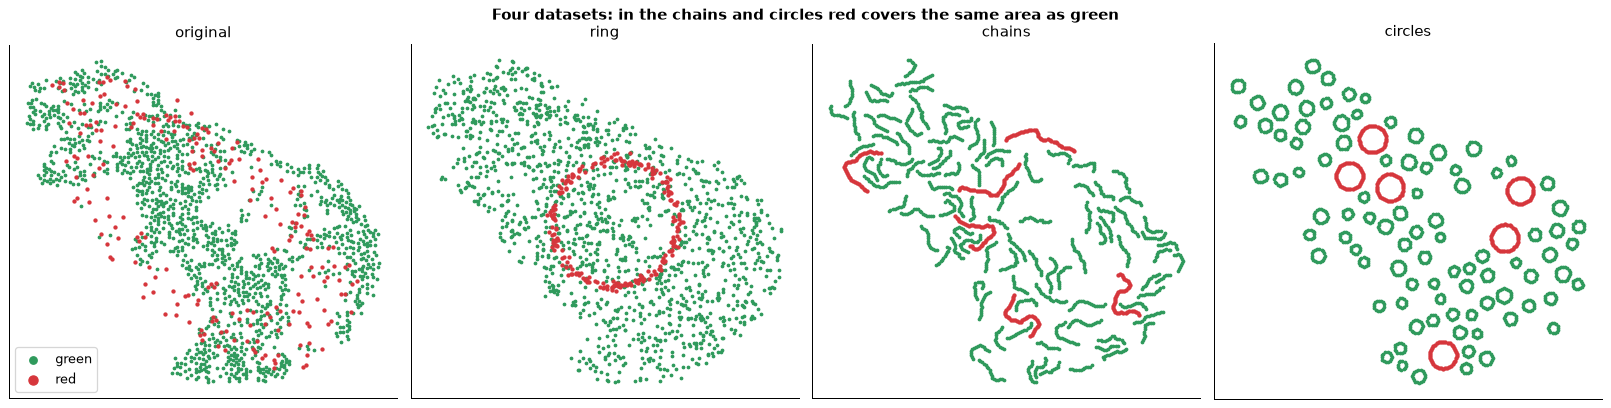

chains   |mean difference| / std = [0.05 0.02],  red/green spread ratio = [0.9  0.84]
circles  |mean difference| / std = [0.19 0.09],  red/green spread ratio = [0.72 0.86]


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (name, (X, y)) in zip(axes, data.items()):
    ax.scatter(*X[y == 0].T, s=4, c=GREEN, label="green")
    ax.scatter(*X[y == 1].T, s=6, c=RED, label="red")
    ax.set_title(name)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(loc="lower left", markerscale=3)
fig.suptitle("Four datasets: in the chains and circles red covers the same area as green", fontweight="bold")
plt.tight_layout()
plt.show()

for name in ("chains", "circles"):
    X, y = data[name]
    shift = np.abs(X[y == 1].mean(0) - X[y == 0].mean(0)) / X.std(0)
    ratio = X[y == 1].std(0) / X[y == 0].std(0)
    print(f"{name:8s} |mean difference| / std = {shift.round(2)},  red/green spread ratio = {ratio.round(2)}")

## 4. The baseline trap

With a red share $p$, labelling *every* point red gives precision $p$, recall 1 and

$$F_1^{\text{all red}} = \frac{2p}{1+p} \approx 0.239 \quad (p = 0.136), \qquad \text{see (1.4)}.$$

Any method scoring near this number has learned nothing. All score-based methods below are
evaluated the same way: a method returns a **score** per point, and the $n_{\text{flag}}$
highest scores are flagged red, where $n_{\text{flag}}$ is the number of red points. This
assumes the class prior is known, the only use of label information in the unsupervised
methods.

In [5]:
for name, (X, y) in data.items():
    print(f"{name:9s} all-red baseline F1 = {baseline_f1(y):.3f}")

original  all-red baseline F1 = 0.239
ring      all-red baseline F1 = 0.235
chains    all-red baseline F1 = 0.239
circles   all-red baseline F1 = 0.239


## 5. Locally, every point looks the same

Take one red and one green point from the walk chains and look around them with the colours
hidden (grey): two neighbours about 12 px away along a line, and nothing else inside the
30 px circle. The right panel compares the distance to the 1st, 2nd and 5th nearest
neighbour for all red and all green points: the curves almost coincide.

The only small difference is at **chain ends**, where the 2nd neighbour is ~24 px away.
Short chains have relatively more ends, so slightly more green points are ends. That hint is
too weak for any local method (see section 7). Circles have no ends at all.

So any method that judges a point by its **neighbourhood** sees the same picture for both
colours: k-NN density, LOF, a classifier on X, Y, even supervised k-NN.

*RU: локально любая точка выглядит одинаково — два соседа на расстоянии ~12 px и никого в
радиусе 30 px; распределения расстояний до соседей у красных и зелёных почти совпадают.*

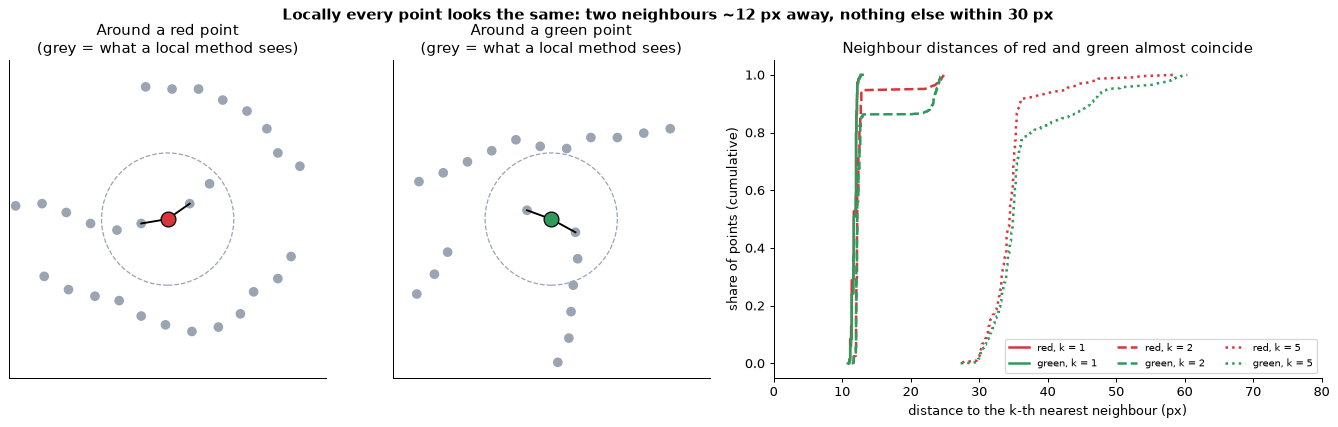

median distance to the 2nd neighbour: red 12.2 px, green 12.2 px
chain ends: 13.7% of green points, 5.3% of red points


In [6]:
X, y = data["chains"]
dist, nbr = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X)

fig = plt.figure(figsize=(15, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.7])
for j, (cls, col, label) in enumerate([(1, RED, "a red point"), (0, GREEN, "a green point")]):
    ax = fig.add_subplot(gs[0, j])
    members = np.where(y == cls)[0]
    i0 = members[len(members) // 2 + 3]
    near = np.linalg.norm(X - X[i0], axis=1) < 70
    ax.scatter(*(X[near] - X[i0]).T, s=60, c=GREY, edgecolors="none")
    ax.scatter(0, 0, s=140, c=col, edgecolors="k", zorder=3)
    for q in nbr[i0, 1:3]:
        ax.plot([0, X[q, 0] - X[i0, 0]], [0, X[q, 1] - X[i0, 1]], c="k", lw=1.5)
    ax.add_patch(plt.Circle((0, 0), 30, fill=False, ls="--", ec=GREY))
    ax.set_xlim(-72, 72); ax.set_ylim(-72, 72); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"Around {label}\n(grey = what a local method sees)")

ax = fig.add_subplot(gs[0, 2])
for k, ls in [(1, "-"), (2, "--"), (5, ":")]:
    for cls, col in [(1, RED), (0, GREEN)]:
        v = np.sort(dist[y == cls, k])
        ax.plot(v, np.linspace(0, 1, len(v)), c=col, ls=ls, lw=2,
                label=f"{'red' if cls else 'green'}, k = {k}")
ax.set_xlim(0, 80)
ax.set_xlabel("distance to the k-th nearest neighbour (px)")
ax.set_ylabel("share of points (cumulative)")
ax.legend(fontsize=8, ncol=3)
ax.set_title("Neighbour distances of red and green almost coincide")
fig.suptitle("Locally every point looks the same: two neighbours ~12 px away, nothing else within 30 px",
             fontweight="bold")
plt.tight_layout()
plt.show()

ends = dist[:, 2] > 18          # 2nd neighbour far away -> the point is a chain end
print(f"median distance to the 2nd neighbour: red {np.median(dist[y == 1, 2]):.1f} px, "
      f"green {np.median(dist[y == 0, 2]):.1f} px")
print(f"chain ends: {ends[y == 0].mean():.1%} of green points, {ends[y == 1].mean():.1%} of red points")

## 6. Graph diagnostic: edge homophily

A graph can only help if its edges connect points of the same class. For a symmetrised k-NN
graph the **edge homophily** is the share of edges whose ends share a colour, and the
**red → red rate** is the share of a red node's edges that lead to another red node. If the
graph had no structure, the red → red rate would equal the share of red points (13.6%).
The colours are used here only to *diagnose* the graph, never to build it.

*RU: гомофилия — доля рёбер между точками одного цвета. Граф полезен, только если рёбра
соединяют точки одного класса.*

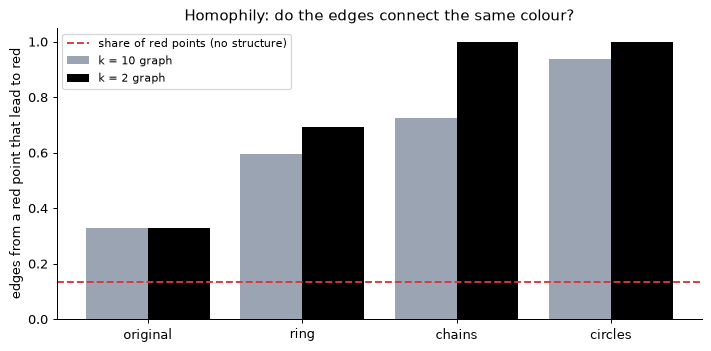

edge homophily               red -> red              
k                    2      5      10         2      5      10
dataset                                                       
original          0.824  0.826  0.822      0.330  0.349  0.327
ring              0.913  0.903  0.883      0.693  0.658  0.595
chains            1.000  0.976  0.926      1.000  0.907  0.726
circles           1.000  1.000  0.983      1.000  0.998  0.937

In [7]:
def homophily(A, y):
    i, j = A.nonzero()
    same = (y[i] == y[j]).mean()
    red = y[i] == 1
    return same, (y[j][red] == 1).mean()


rows = []
for name, (X, y) in data.items():
    for k in (2, 5, 10):
        same, rr = homophily(knn_adjacency(X, k), y)
        rows.append({"dataset": name, "k": k, "edge homophily": same, "red -> red": rr})
homophily_table = pd.DataFrame(rows).pivot(index="dataset", columns="k").loc[list(FILES)]

fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(FILES))
for off, k, col in [(-0.2, 10, GREY), (0.2, 2, "k")]:
    ax.bar(xx + off, homophily_table[("red -> red", k)], 0.4, color=col, label=f"k = {k} graph")
ax.axhline(data["chains"][1].mean(), ls="--", c=RED, label="share of red points (no structure)")
ax.set_xticks(xx, list(FILES)); ax.set_ylim(0, 1.05)
ax.set_ylabel("edges from a red point that lead to red")
ax.set_title("Homophily: do the edges connect the same colour?")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
homophily_table.round(3)

On the original data only about a third of a red node's edges lead to red, so any
message passing averages red with green. On the ring it is about two thirds. On the chains
and circles with $k = 2$ **every** edge stays inside one class: the chain step (12 px) is
smaller than the gap between chains (30 px), so a point's two nearest neighbours are always
its own chain neighbours.

## 7. Methods on four datasets

All methods see only $X, Y$.

| Method | Score per point |
|---|---|
| k-NN density | $1 / d_k$, the inverse distance to the $k$-th neighbour ($k = 10$) |
| k-NN sparsity | $d_k$ ($k = 10$): red sits in emptier spots in the original data |
| LOF | local outlier factor ($k = 20$) |
| Graph: smoothed density | one GCN-style step $\hat{A}\,(1/d_k)$ with $\hat{A} = D^{-1/2}(A+I)D^{-1/2}$ |
| **Graph: connected components** | size of the point's component in the $k = 2$ k-NN graph |

The first three are **local**: they look at a fixed neighbourhood. Smoothed density is a graph
method that **averages** over neighbours, like one GCN layer. Connected components
**follow edges** as far as they go.

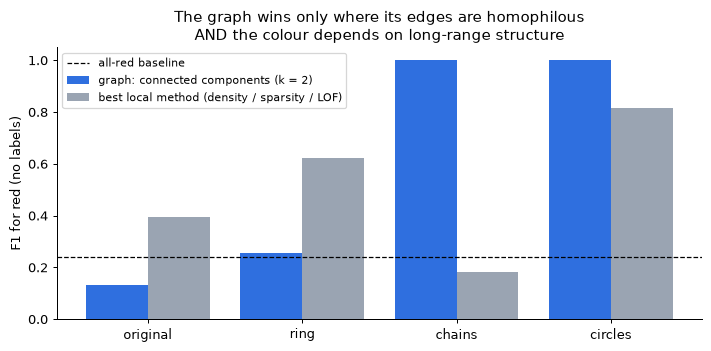

,original,ring,chains,circles
all red (baseline),0.239,0.235,0.239,0.239
k-NN density (k=10),0.040,0.621,0.181,0.000
k-NN sparsity (k=10),0.396,0.000,0.031,0.815
LOF (k=20),0.322,0.013,0.070,0.220
Graph: smoothed density,0.035,0.648,0.211,0.000
Graph: connected components (k=2),0.132,0.256,1.000,1.000


In [8]:
def gcn_smooth(A, v):
    A = A.tolil(copy=True)
    A.setdiag(1.0)
    A = A.tocsr()
    dinv = 1 / np.sqrt(np.asarray(A.sum(1)).ravel())
    return dinv * (A @ (dinv * v))


METHODS = {
    "k-NN density (k=10)": lambda X: 1 / kth_distance(X, 10),
    "k-NN sparsity (k=10)": lambda X: kth_distance(X, 10),
    "LOF (k=20)": lambda X: -LocalOutlierFactor(20).fit(X).negative_outlier_factor_,
    "Graph: smoothed density": lambda X: gcn_smooth(knn_adjacency(X, 10), 1 / kth_distance(X, 10)),
    "Graph: connected components (k=2)": lambda X: components(X, 2)[1],
}

scores = {}
for name, (X, y) in data.items():
    scores[name] = {"all red (baseline)": baseline_f1(y)}
    for method, fn in METHODS.items():
        scores[name][method] = f1_top(y, fn(X))
results = pd.DataFrame(scores)

local = ["k-NN density (k=10)", "k-NN sparsity (k=10)", "LOF (k=20)"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(xx - 0.2, results.loc["Graph: connected components (k=2)"], 0.4, color=BLUE,
       label="graph: connected components (k = 2)")
ax.bar(xx + 0.2, results.loc[local].max(), 0.4, color=GREY, label="best local method (density / sparsity / LOF)")
ax.axhline(baseline_f1(data["chains"][1]), ls="--", c="k", lw=1, label="all-red baseline")
ax.set_xticks(xx, list(FILES)); ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 for red (no labels)")
ax.set_title("The graph wins only where its edges are homophilous\nAND the colour depends on long-range structure")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
results.round(3)

**Reading the table.**

- **Original:** only the sparsity-type scores (k-NN sparsity, LOF) clear the baseline: red
  points sit in slightly emptier spots. The graph adds nothing, because its edges mix the colours.
- **Ring:** density methods work, and one smoothing step helps a little, since the ring is
  denser than the background. Components fail: the ring is not a chain.
- On the original and ring data the  = 2$ graph does not split by colour, so many points
  share the same component size and the tie is broken at random: the component score there
  is no better than the baseline.
- **Chains:** every local method stays at or below the baseline, while connected
  components reach F1 = 1.000. The colour is a property of the whole chain, not of a
  neighbourhood.
- **Circles:** components again reach 1.000. This set is a weaker test: a small circle keeps
  all its points within one diameter, so k-NN sparsity at $k = 10$ also picks up a local
  signal. The walk chains are the stricter example, where *only* connectivity differs.

The next three sections explain the chain result step by step.

## 8. With k = 2, the graph's components are exactly the chains

Link every point to its 2 nearest neighbours and colour each connected component
differently (left). Because the step along a chain is smaller than the gap between chains,
the graph falls apart into one component per chain, and no component mixes colours. The red
labels mark the six red chains and their sizes.

The histogram (right) shows the consequence: **component size separates the colours
perfectly**. Green chains have 9–20 points (circles 12–20) and red ones 37–38, so any threshold in the gold
band gives F1 = 1, with no labels.

*RU: при k = 2 компоненты связности графа совпадают с цепочками; размер компоненты идеально
разделяет цвета.*

chains   components = 105, mixed-colour components = 0, edges joining the same colour = 100%, green sizes 9-20, red sizes 37-38
circles  components = 97, mixed-colour components = 0, edges joining the same colour = 100%, green sizes 12-20, red sizes 37-38


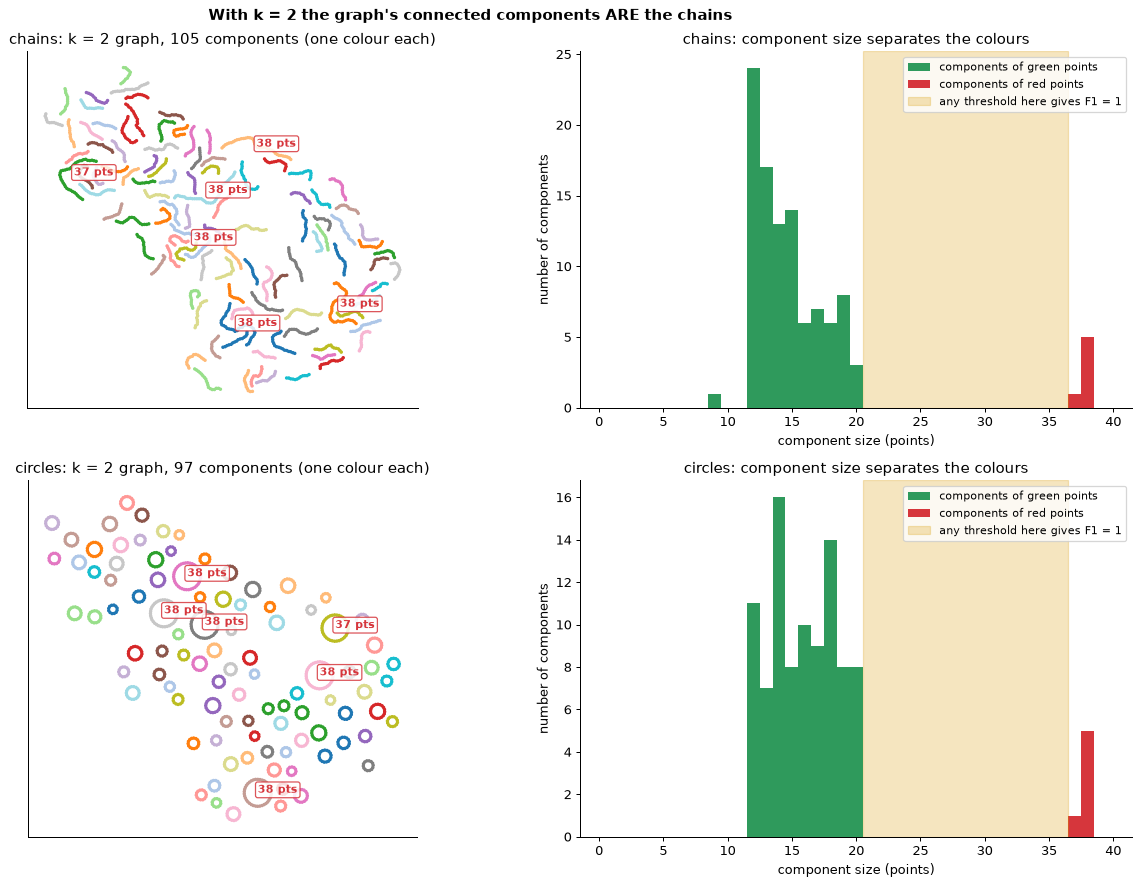

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1.5, 1]})
cmap = plt.get_cmap("tab20")
for row, name in zip(axes, ("chains", "circles")):
    X, y = data[name]
    lab, size, n_comp = components(X, 2)
    r, c = sparse.triu(knn_adjacency(X, 2)).nonzero()

    ax = row[0]
    ax.add_collection(LineCollection(np.stack([X[r], X[c]], axis=1),
                                     colors=[cmap(lab[i] % 20) for i in r], linewidths=1.6))
    ax.scatter(*X.T, s=3, c=[cmap(l % 20) for l in lab])
    for comp in np.unique(lab[y == 1]):
        m = lab == comp
        ax.annotate(f"{m.sum()} pts", X[m].mean(0), fontsize=9, fontweight="bold", color=RED,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=RED, alpha=0.85))
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}: k = 2 graph, {n_comp} components (one colour each)")

    ax = row[1]
    sizes = np.bincount(lab)
    red_share = np.bincount(lab, weights=y) / sizes
    mixed = ((red_share > 0) & (red_share < 1)).sum()
    red_comp = red_share > 0.5
    bins = np.arange(0, sizes.max() + 2) + 0.5       # one bar per integer size
    ax.hist(sizes[~red_comp], bins=bins, color=GREEN, label="components of green points")
    ax.hist(sizes[red_comp], bins=bins, color=RED, label="components of red points")
    ax.axvspan(sizes[~red_comp].max() + 0.5, sizes[red_comp].min() - 0.5, color=GOLD, alpha=0.25,
               label="any threshold here gives F1 = 1")
    ax.set_xlabel("component size (points)"); ax.set_ylabel("number of components")
    ax.set_title(f"{name}: component size separates the colours")
    ax.legend(fontsize=9)
    same, _ = homophily(knn_adjacency(X, 2), y)
    print(f"{name:8s} components = {n_comp}, mixed-colour components = {mixed}, edges joining the same colour = {same:.0%}, "
          f"green sizes {sizes[~red_comp].min()}-{sizes[~red_comp].max()}, red sizes {sizes[red_comp].min()}-{sizes[red_comp].max()}")
fig.suptitle("With k = 2 the graph's connected components ARE the chains", fontweight="bold")
plt.tight_layout()
plt.show()

## 9. The colour is a long-range property

How many points can a point reach within $h$ hops along the $k = 2$ graph?

- **h = 1–3 hops:** red and green reach the same number of points (3, 5, 7, …), because
  locally they are identical (section 5).
- **Beyond ~6 hops:** green chains end (12–20 points), while red chains keep going up to ~38.
- **Right panel:** flag the points with the largest $h$-hop reach as red. For small $h$ this
  is no better than the baseline; F1 rises after 6–8 hops and reaches 1.000 at about half the
  length of a red chain. Connected components are the limit $h \to \infty$.

This is the core of the explanation: the information that decides the colour is not near the
point, it is at the end of its chain. A method has to **follow the chain all the way**. Graph
traversal does that; any fixed-radius method cannot. It also explains why GCN-style
averaging does worse: averaging mixes values and fades after a few hops, whereas following
edges is transitive, so a point in the middle of a red chain is linked to all ~38 points.

*RU: цвет — дальнее свойство. На 1–3 шагах красные и зелёные точки неотличимы; различие
появляется, только если пройти по цепочке до конца.*

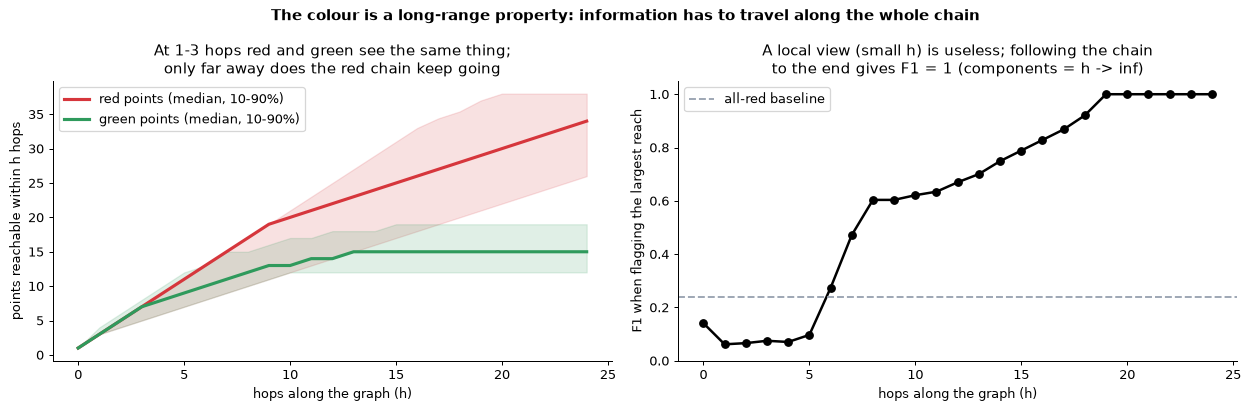

F1 by hops: h=1:0.06 h=3:0.07 h=5:0.10 h=8:0.60 h=12:0.67 h=16:0.83 h=20:1.00 h=24:1.00


In [10]:
X, y = data["chains"]
D = shortest_path(knn_adjacency(X, 2), unweighted=True, directed=False)   # hop distances (inf = unreachable)
hops = np.arange(0, 25)
reach = np.array([(D <= h).sum(1) for h in hops])                           # points reachable within h hops
f1_h = [f1_top(y, reach[i]) for i in range(len(hops))]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
for cls, col in [(1, RED), (0, GREEN)]:
    med = np.median(reach[:, y == cls], axis=1)
    lo, hi = np.percentile(reach[:, y == cls], [10, 90], axis=1)
    ax.plot(hops, med, c=col, lw=2.5, label=f"{'red' if cls else 'green'} points (median, 10-90%)")
    ax.fill_between(hops, lo, hi, color=col, alpha=0.15)
ax.set_xlabel("hops along the graph (h)"); ax.set_ylabel("points reachable within h hops")
ax.set_title("At 1-3 hops red and green see the same thing;\nonly far away does the red chain keep going")
ax.legend()
ax = axes[1]
ax.plot(hops, f1_h, "o-", c="k", lw=2)
ax.axhline(baseline_f1(y), ls="--", c=GREY, label="all-red baseline")
ax.set_ylim(0, 1.05)
ax.set_xlabel("hops along the graph (h)"); ax.set_ylabel("F1 when flagging the largest reach")
ax.set_title("A local view (small h) is useless; following the chain\nto the end gives F1 = 1 (components = h -> inf)")
ax.legend()
fig.suptitle("The colour is a long-range property: information has to travel along the whole chain", fontweight="bold")
plt.tight_layout()
plt.show()
print("F1 by hops:", " ".join(f"h={h}:{v:.2f}" for h, v in zip(hops, f1_h) if h in (1, 3, 5, 8, 12, 16, 20, 24)))

## 10. Choosing k: the graph must not add edges between chains

A chain point has exactly two neighbours, so $k = 2$ matches the structure.

- **k = 1** is too small: chains break into pairs and short pieces.
- **Walk chains, k ≥ 3:** extra edges jump to *other* chains (gold edges in the middle and
  right panels), the components merge, and F1 collapses.
- **Circles** tolerate $k = 3$–$4$, because the extra edges cross *inside* the same circle.

The general requirement: the graph must reproduce the true connections, with **no edges
between classes**. Choosing $k$ is part of the model, not a detail.

*RU: k = 2 соответствует структуре цепочки; при большем k появляются рёбра между цепочками
(золотые), компоненты сливаются и F1 падает.*

chains    k=1:0.16 k=2:1.00 k=3:0.28 k=4:0.14 k=5:0.14 k=6:0.14 k=7:0.14 k=8:0.14
circles   k=1:0.14 k=2:1.00 k=3:1.00 k=4:1.00 k=5:0.30 k=6:0.33 k=7:0.36 k=8:0.17
ring      k=1:0.11 k=2:0.26 k=3:0.12 k=4:0.13 k=5:0.13 k=6:0.13 k=7:0.13 k=8:0.13
original  k=1:0.16 k=2:0.13 k=3:0.14 k=4:0.14 k=5:0.14 k=6:0.14 k=7:0.14 k=8:0.14


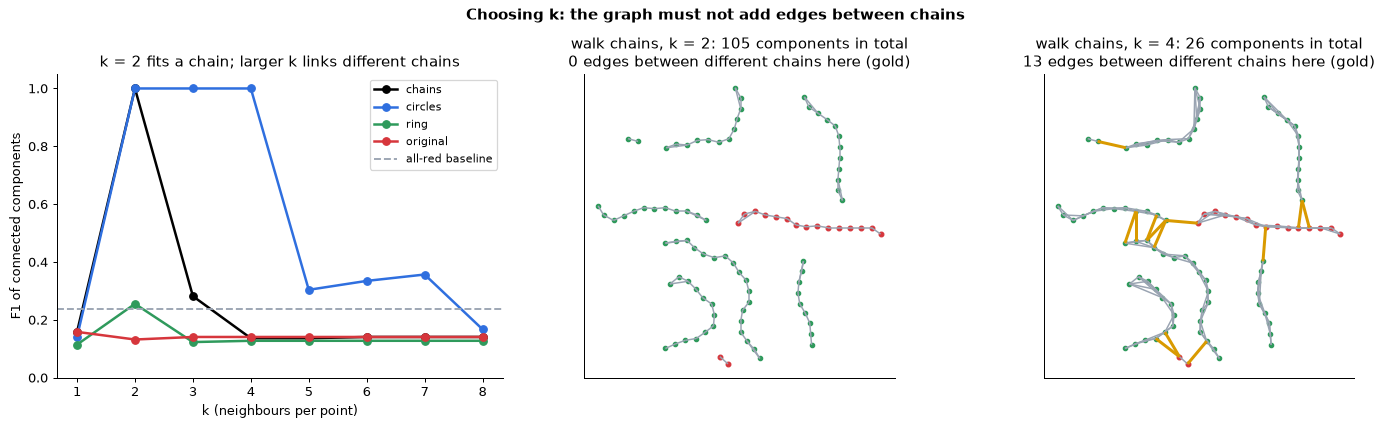

In [11]:
ks = range(1, 9)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
for name, col in [("chains", "k"), ("circles", BLUE), ("ring", GREEN), ("original", RED)]:
    X, y = data[name]
    f1s = [f1_top(y, components(X, k)[1]) for k in ks]
    ax.plot(list(ks), f1s, "o-", c=col, lw=2, label=name)
    print(f"{name:9s}", " ".join(f"k={k}:{v:.2f}" for k, v in zip(ks, f1s)))
ax.axhline(baseline_f1(data["chains"][1]), ls="--", c=GREY, label="all-red baseline")
ax.set_ylim(0, 1.05)
ax.set_xlabel("k (neighbours per point)"); ax.set_ylabel("F1 of connected components")
ax.set_title("k = 2 fits a chain; larger k links different chains")
ax.legend(fontsize=9)

X, y = data["chains"]
true_chain, _, _ = components(X, 2)                     # at k = 2 the components are the true chains
i0 = np.where(y == 1)[0][0]
window = np.linalg.norm(X - X[i0], axis=1) < 160
for ax, k in zip(axes[1:], (2, 4)):
    _, _, n_comp = components(X, k)
    r, c = sparse.triu(knn_adjacency(X, k)).nonzero()
    keep = window[r] & window[c]
    cross = true_chain[r] != true_chain[c]                # edge between two different chains
    ax.add_collection(LineCollection(np.stack([X[r[keep & ~cross]], X[c[keep & ~cross]]], 1), colors=GREY, lw=1.2))
    ax.add_collection(LineCollection(np.stack([X[r[keep & cross]], X[c[keep & cross]]], 1), colors=GOLD, lw=2.4))
    ax.scatter(*X[window & (y == 0)].T, s=12, c=GREEN)
    ax.scatter(*X[window & (y == 1)].T, s=14, c=RED)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"walk chains, k = {k}: {n_comp} components in total\n"
                 f"{(keep & cross).sum()} edges between different chains here (gold)")
fig.suptitle("Choosing k: the graph must not add edges between chains", fontweight="bold")
plt.tight_layout()
plt.show()

## 11. All methods on the walk chains, supervised ones included

The strongest test: give some methods the true colours. Supervised scores are computed out of
fold (5-fold stratified cross-validation), so no point is predicted by a model that saw its
own colour.

| Method | Uses labels? | Idea |
|---|---|---|
| connected components (k = 2) | no | follow the chain to its end |
| k-NN density / sparsity, LOF | no | local neighbourhood |
| K-Means, GMM | no | global position |
| graph: smoothed density | no | one averaging step on the k = 10 graph |
| k-NN classifier (15 neighbours) | **yes** | majority colour of the neighbours |
| graph label spreading | **yes** | propagate known colours along the k = 10 graph |
| logistic regression, degree 4 | **yes** | smooth boundary in X, Y |

Even the supervised methods lose. They know the colours, but they still judge a point by its
neighbourhood or its position, and neither contains the answer.

*RU: даже методы с учителем проигрывают: они знают цвета, но судят о точке по окрестности
или положению, а ответа там нет.*

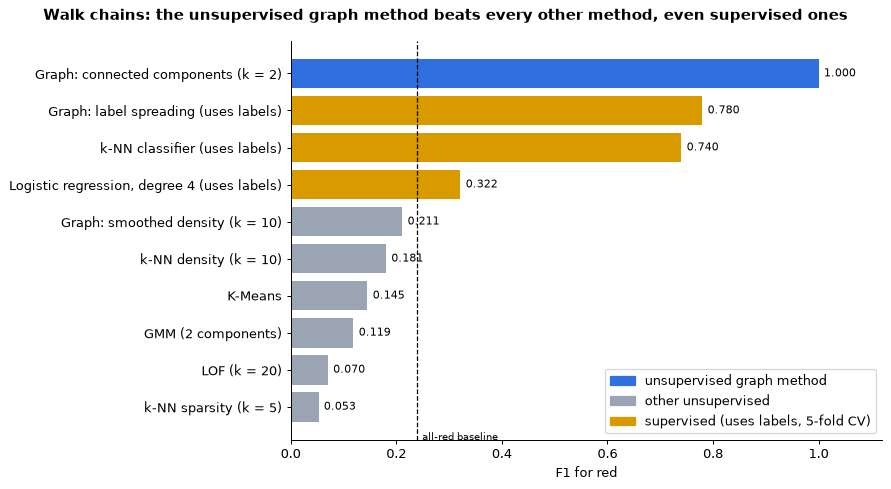

,method,F1,kind
0,Graph: connected components (k = 2),1.000,graph
1,Graph: label spreading (uses labels),0.780,sup
2,k-NN classifier (uses labels),0.740,sup
3,"Logistic regression, degree 4 (uses labels)",0.322,sup
4,Graph: smoothed density (k = 10),0.211,unsup
5,k-NN density (k = 10),0.181,unsup
6,K-Means,0.145,unsup
7,GMM (2 components),0.119,unsup
8,LOF (k = 20),0.070,unsup
9,k-NN sparsity (k = 5),0.053,unsup


In [12]:
X, y = data["chains"]
n = int(y.sum())
Z = StandardScaler().fit_transform(X)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# k = 10 graph with GCN normalisation, shared by smoothed density and label spreading
A10 = knn_adjacency(X, 10)
S = A10 + sparse.eye(len(y))
Dm = sparse.diags(np.asarray(S.sum(1)).ravel() ** -0.5)
S = (Dm @ S @ Dm).tocsr()

minority = lambda lab: lab if lab.mean() < 0.5 else 1 - lab     # cluster -> colour without labels
gmm = GaussianMixture(2, n_init=5, random_state=0).fit(Z).predict_proba(Z)

# supervised 1: k-NN classifier, out of fold
knn_score = np.zeros(len(y))
for tr, te in cv.split(X, y):
    idx = NearestNeighbors(n_neighbors=15).fit(X[tr]).kneighbors(X[te])[1]
    knn_score[te] = y[tr][idx].mean(1)

# supervised 2: label spreading on the graph, class-balanced seeds from the training fold only
lp_score = np.zeros(len(y))
for tr, te in cv.split(X, y):
    Y0 = np.zeros((len(y), 2))
    Y0[tr, y[tr]] = 1
    Y0[tr] /= np.array([[(y[tr] == 0).sum(), (y[tr] == 1).sum()]])
    F = Y0.copy()
    for _ in range(50):                          # F <- 0.9 S F + 0.1 Y0
        F = 0.9 * (S @ F) + 0.1 * Y0
    lp_score[te] = (F[:, 1] / (F.sum(1) + 1e-12))[te]

# supervised 3: polynomial logistic regression, out of fold
P4 = StandardScaler().fit_transform(PolynomialFeatures(4, include_bias=False).fit_transform(Z))
lr_score = cross_val_predict(LogisticRegression(C=1e4, class_weight="balanced", max_iter=20000),
                             P4, y, cv=cv, method="predict_proba")[:, 1]

res = [
    ("Graph: connected components (k = 2)", f1_top(y, components(X, 2)[1]), "graph"),
    ("k-NN density (k = 10)", f1_top(y, 1 / kth_distance(X, 10)), "unsup"),
    ("k-NN sparsity (k = 5)", f1_top(y, kth_distance(X, 5)), "unsup"),
    ("LOF (k = 20)", f1_top(y, -LocalOutlierFactor(20).fit(X).negative_outlier_factor_), "unsup"),
    ("K-Means", f1_score(y, minority(KMeans(2, n_init=10, random_state=0).fit_predict(Z))), "unsup"),
    ("GMM (2 components)", max(f1_top(y, gmm[:, 0]), f1_top(y, gmm[:, 1])), "unsup"),
    ("Graph: smoothed density (k = 10)", f1_top(y, S @ (1 / kth_distance(X, 10))), "unsup"),
    ("k-NN classifier (uses labels)", f1_top(y, knn_score), "sup"),
    ("Graph: label spreading (uses labels)", f1_top(y, lp_score), "sup"),
    ("Logistic regression, degree 4 (uses labels)", f1_top(y, lr_score), "sup"),
]
res.sort(key=lambda r: r[1])

colors = {"graph": BLUE, "unsup": GREY, "sup": GOLD}
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh([r[0] for r in res], [r[1] for r in res], color=[colors[r[2]] for r in res])
for i, r in enumerate(res):
    ax.text(r[1] + 0.01, i, f"{r[1]:.3f}", va="center", fontsize=9)
ax.axvline(baseline_f1(y), ls="--", c="k", lw=1)
ax.text(baseline_f1(y) + 0.01, -0.9, "all-red baseline", fontsize=8)
ax.set_xlim(0, 1.12)
ax.set_xlabel("F1 for red")
ax.legend(handles=[Patch(color=BLUE, label="unsupervised graph method"),
                   Patch(color=GREY, label="other unsupervised"),
                   Patch(color=GOLD, label="supervised (uses labels, 5-fold CV)")], loc="lower right")
fig.suptitle("Walk chains: the unsupervised graph method beats every other method, even supervised ones",
             fontweight="bold")
plt.tight_layout()
plt.show()
pd.DataFrame(res[::-1], columns=["method", "F1", "kind"]).round(3)

## 12. Takeaways

**The rule (1.15).** An unsupervised graph method beats local methods when **both** hold:

1. **Homophilous edges:** the graph connects points of the same class (here: step 12 px < gap
   30 px, and $k = 2$). If this fails, propagation mixes the classes (original, ring).
2. **A long-range class signal:** the class depends on structure that only shows up far away,
   such as path length, components or communities, not on local density or position. If this
   fails, a plain k-NN method is just as good and simpler.

**Practical lessons.**

- **Always report the trivial baseline** $2p/(1+p)$.
- **Build edges from the features only.** Edges that join points of the same `Type` (or any
  label proxy) leak the answer; the older research notebook
  `research-notebooks/Graph from DataFrame tSNE.ipynb` did this, and it is now disabled there.
- **The graph must match the structure:** the wrong $k$ adds edges between classes and the
  advantage disappears.
- **Averaging is not traversal:** GCN-style smoothing fades after a few hops; when the signal is
  long-range, use operations that follow edges (components, shortest paths, many layers).

**Выводы (RU).** Граф выигрывает только при (1) гомофильных рёбрах и (2) классе, зависящем от
дальней структуры (пути, компоненты). Рёбра строятся только по признакам: рёбра по `Type`
дают утечку метки. Неправильный $k$ соединяет разные цепочки и убирает преимущество.
Усреднение (GCN) затухает за несколько шагов, а обход графа — нет.

Full study with 20+ methods, a hyperbolic GCN and an in-browser lab:
[ML-overlay-problem](https://github.com/D2718281828nis/ML-overlay-problem) ·
[illustrations](https://github.com/D2718281828nis/ML-overlay-problem/blob/main/illustrations/README.md).